In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import src.preprocessing
import importlib

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import time
from IPython.display import clear_output

from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    GridSearchCV,
    PredefinedSplit
)

import shap
from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    auc,
    log_loss
)

/Volumes/Kingston/Alesia/vs_projects/kkbox_churn/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
BASE_DIR = Path("..")
DATA_PROCESSED = BASE_DIR / "data" / "processed"

TRAIN_DATA_PATH = DATA_PROCESSED / "train_features.csv"
TEST_DATA_PATH = DATA_PROCESSED / "test_features.csv"

RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 5
N_JOBS = -1

TARGET_COL = "is_churn"
ID_COL = "msno"

### 1. Loading Data and Creating Training, Validation, and Test Sets

In [3]:
train_features = pd.read_csv(TRAIN_DATA_PATH)

In [4]:
test_features = pd.read_csv(TEST_DATA_PATH)

In [5]:
train_features.shape, test_features.shape

((992931, 39), (970960, 39))

In [6]:
train_features[TARGET_COL].value_counts(normalize=True), test_features[TARGET_COL].value_counts(normalize=True)

(is_churn
 0    0.936077
 1    0.063923
 Name: proportion, dtype: float64,
 is_churn
 0    0.910058
 1    0.089942
 Name: proportion, dtype: float64)

In [7]:
X = train_features.drop(
    columns=[ID_COL, TARGET_COL]
)

y = train_features[TARGET_COL]

In [8]:
X_test = test_features.drop(
    columns=[ID_COL, TARGET_COL]
)

y_test = test_features[TARGET_COL]

In [9]:
X.shape, y.shape

((992931, 37), (992931,))

 Train 1 is the February expiry cohort. This stratified random split is used for model and hyperparameter selection within that cohort.

In [10]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

In [11]:
importlib.reload(src.preprocessing)
numeric_cols, categorical_cols = src.preprocessing.get_feature_columns(X)

In [12]:
for col in categorical_cols:
    types = X_train[col].dropna().map(type).value_counts()
    if len(types) > 1:
        print(col, types.to_dict())

In [13]:
for col in numeric_cols:
    types = X_train[col].dropna().map(type).value_counts()
    if len(types) > 1:
        print(col, types.to_dict())

In [14]:
preprocessor_sparse = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric_cols
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=True
                ))
            ]),
            categorical_cols
        )
    ]
)

In [15]:
preprocessor_dense = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric_cols
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            categorical_cols
        )
    ]
)

### 2. Model Training and Final Model Selection

Training models with and without class weights

In [16]:
models_without = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor_sparse),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor_sparse),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=16,
            random_state=RANDOM_STATE,
            n_jobs=N_JOBS
        ))
    ]),

    "HistGradientBoosting": Pipeline([
        ("preprocessor", preprocessor_dense),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=300,
            random_state=RANDOM_STATE
        ))
    ]),
    "XGBoost": Pipeline([
        ("preprocessor", preprocessor_sparse),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.1,
            tree_method="hist",
            random_state=RANDOM_STATE,
            n_jobs=N_JOBS
        ))
    ]),
    "LightGBM": Pipeline([
        ("preprocessor", preprocessor_sparse),
        ("classifier", LGBMClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.1,
            random_state=RANDOM_STATE,
            verbose = -1,
            n_jobs=N_JOBS
        ))
    ])
}

In [17]:
scale_pos_weight_val = (y_train == 0).sum() / (y_train == 1).sum()

models_with = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor_sparse),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor_sparse),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=16,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=N_JOBS
        ))
    ]),

    "HistGradientBoosting": Pipeline([
        ("preprocessor", preprocessor_dense),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=300,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),
    "XGBoost": Pipeline([
        ("preprocessor", preprocessor_sparse),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.1,
            scale_pos_weight=scale_pos_weight_val,
            tree_method="hist",
            random_state=RANDOM_STATE,
            n_jobs=N_JOBS
        ))
    ]),
    "LightGBM": Pipeline([
        ("preprocessor", preprocessor_sparse),
        ("classifier", LGBMClassifier(
            n_estimators=300,
            max_depth=6,
            learning_rate=0.1,
            scale_pos_weight=scale_pos_weight_val,
            random_state=RANDOM_STATE,
            verbose = -1,
            n_jobs=N_JOBS
        ))
    ])
}

In [18]:
results_without = []

for name, model in models_without.items():

    print(f"\nTraining: {name}")

    start_time = time.time()

    model.fit(X_train, y_train)

    train_proba = model.predict_proba(X_train)[:, 1]
    valid_proba = model.predict_proba(X_valid)[:, 1]

    train_ap = average_precision_score(y_train, train_proba)
    valid_ap = average_precision_score(y_valid, valid_proba)

    elapsed = time.time() - start_time
    
    results_without.append({
        "model": name,
        "train_ap": train_ap,
        "valid_ap": valid_ap,
        "ap_gap": train_ap - valid_ap,
        "training_time_sec": elapsed
    })
    
    print(f"Train AP: {train_ap:.4f}")
    print(f"Valid AP: {valid_ap:.4f}")
    print(f"AP gap: {train_ap - valid_ap:.4f}")
    print(f"Training time: {elapsed:.1f} sec")


Training: Logistic Regression


/Volumes/Kingston/Alesia/vs_projects/kkbox_churn/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Train AP: 0.2206
Valid AP: 0.2179
AP gap: 0.0027
Training time: 92.2 sec

Training: Random Forest
Train AP: 0.6392
Valid AP: 0.4824
AP gap: 0.1568
Training time: 145.5 sec

Training: HistGradientBoosting
Train AP: 0.5405
Valid AP: 0.5092
AP gap: 0.0313
Training time: 33.2 sec

Training: XGBoost
Train AP: 0.5684
Valid AP: 0.5114
AP gap: 0.0570
Training time: 16.4 sec

Training: LightGBM
Train AP: 0.5495
Valid AP: 0.5097
AP gap: 0.0399
Training time: 13.1 sec


In [19]:
results_with = []

for name, model in models_with.items():

    print(f"\nTraining: {name}")

    start_time = time.time()

    model.fit(X_train, y_train)

    train_proba = model.predict_proba(X_train)[:, 1]
    valid_proba = model.predict_proba(X_valid)[:, 1]

    train_ap = average_precision_score(y_train, train_proba)
    valid_ap = average_precision_score(y_valid, valid_proba)

    elapsed = time.time() - start_time
    
    results_with.append({
        "model": name,
        "train_ap": train_ap,
        "valid_ap": valid_ap,
        "ap_gap": train_ap - valid_ap,
        "training_time_sec": elapsed
    })
    
    print(f"Train AP: {train_ap:.4f}")
    print(f"Valid AP: {valid_ap:.4f}")
    print(f"AP gap: {train_ap - valid_ap:.4f}")
    print(f"Training time: {elapsed:.1f} sec")


Training: Logistic Regression


/Volumes/Kingston/Alesia/vs_projects/kkbox_churn/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Train AP: 0.2361
Valid AP: 0.2332
AP gap: 0.0029
Training time: 92.4 sec

Training: Random Forest
Train AP: 0.6318
Valid AP: 0.4427
AP gap: 0.1890
Training time: 109.0 sec

Training: HistGradientBoosting
Train AP: 0.5037
Valid AP: 0.4914
AP gap: 0.0123
Training time: 30.0 sec

Training: XGBoost
Train AP: 0.5405
Valid AP: 0.4983
AP gap: 0.0422
Training time: 16.5 sec

Training: LightGBM
Train AP: 0.5220
Valid AP: 0.4987
AP gap: 0.0232
Training time: 13.4 sec


For a random ranking, Average Precision is approximately the positive-class prevalence. 

This provides a baseline for interpreting the AP score.

In [20]:
print("Random baseline Average Precision:", y_valid.mean())

Random baseline Average Precision: 0.0639216061474316


In [21]:
model_results_without = (
    pd.DataFrame(results_without)
    .sort_values("valid_ap", ascending=False)
    .reset_index(drop=True)
)

model_results_without

,model,train_ap,valid_ap,ap_gap,training_time_sec
0,XGBoost,0.568413,0.511378,0.057035,16.409242
1,LightGBM,0.549547,0.509680,0.039867,13.120499
2,HistGradientBoosting,0.540491,0.509209,0.031283,33.180585
3,Random Forest,0.639174,0.482402,0.156772,145.499895
4,Logistic Regression,0.220580,0.217883,0.002697,92.161576


In [22]:
model_results_with   = (
    pd.DataFrame(results_with)
    .sort_values("valid_ap", ascending=False)
    .reset_index(drop=True)
)

model_results_with

,model,train_ap,valid_ap,ap_gap,training_time_sec
0,LightGBM,0.521953,0.498731,0.023223,13.422613
1,XGBoost,0.540473,0.498310,0.042162,16.508578
2,HistGradientBoosting,0.503714,0.491371,0.012343,29.980326
3,Random Forest,0.631761,0.442723,0.189038,109.001465
4,Logistic Regression,0.236079,0.233175,0.002904,92.369107


The predefined split uses the training portion for fitting and the validation portion for scoring each parameter setting. 

RandomizedSearchCV refits the selected pipeline on all of X_full when refit=True.

In [23]:
X_full = pd.concat([X_train, X_valid], axis=0)
y_full = pd.concat([y_train, y_valid], axis=0)

split_index = [-1] * len(X_train) + [0] * len(X_valid)
pds = PredefinedSplit(test_fold=split_index)


In [24]:
xgb_param_grid = {
    "classifier__n_estimators": [200, 300, 500, 700],
    "classifier__max_depth": [3, 4, 5, 6, 8],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__min_child_weight": [1, 3, 5, 10],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__gamma": [0, 0.1, 0.3, 0.5],
    "classifier__scale_pos_weight": [1, 2, 3]
}

random_search_xgb = RandomizedSearchCV(
    estimator=models_without["XGBoost"],
    param_distributions=xgb_param_grid,
    n_iter=20,
    scoring="average_precision",
    cv=pds,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
    refit=True
)

random_search_xgb.fit(X_full, y_full)
clear_output(wait=True)
print("RandomizedSearchCV for XGBoost is complete. Best parameters found: ", random_search_xgb.best_params_)

RandomizedSearchCV for XGBoost is complete. Best parameters found:  {'classifier__subsample': 0.9, 'classifier__scale_pos_weight': 1, 'classifier__n_estimators': 500, 'classifier__min_child_weight': 3, 'classifier__max_depth': 8, 'classifier__learning_rate': 0.05, 'classifier__gamma': 0.1, 'classifier__colsample_bytree': 0.8}


In [25]:
light_param_grid = {
    "classifier__num_leaves": [15, 31, 63, 127],
    "classifier__max_depth": [-1, 5, 8, 12],
    "classifier__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "classifier__n_estimators": [200, 400, 600],
    "classifier__subsample": [0.7, 0.8, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 1.0],
    "classifier__scale_pos_weight": [1, 2, 3]
}

random_search_light = RandomizedSearchCV(
    estimator=models_without["LightGBM"],
    param_distributions=light_param_grid,
    n_iter=20,
    scoring="average_precision",
    cv=pds,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
    refit=True
)

random_search_light.fit(X_full, y_full)
clear_output(wait=True)
print("RandomizedSearchCV for LightGBM is complete. Best parameters found: ", random_search_light.best_params_)

RandomizedSearchCV for LightGBM is complete. Best parameters found:  {'classifier__subsample': 0.8, 'classifier__scale_pos_weight': 3, 'classifier__num_leaves': 127, 'classifier__n_estimators': 200, 'classifier__max_depth': -1, 'classifier__learning_rate': 0.05, 'classifier__colsample_bytree': 0.7}


X_test is the later March expiry cohort and serves as temporal validation.

These results are used to assess performance under a later cohort and cutoff.

In [26]:
random_xgb = random_search_xgb.best_estimator_
y_pred_random_xgb = random_xgb.predict_proba(X_test)[:, 1]
ap_random_xgb = average_precision_score(y_test, y_pred_random_xgb)

print("Best Average Precision for XGBoost:", ap_random_xgb)

Best Average Precision for XGBoost: 0.5218372540850466


In [27]:
random_light = random_search_light.best_estimator_
y_pred_random_light = random_light.predict_proba(X_test)[:, 1]
ap_random_light = average_precision_score(y_test, y_pred_random_light)

print("Best Average Precision for LightGBM:", ap_random_light)

Best Average Precision for LightGBM: 0.526351370517469


In [28]:
best_random_params = random_search_light.best_params_

grid_estimator = clone(random_light)

light_param_grid_fine = {
    "classifier__n_estimators": [
        max(100, best_random_params["classifier__n_estimators"] - 50),
        best_random_params["classifier__n_estimators"],
        best_random_params["classifier__n_estimators"] + 50,
    ],
    "classifier__max_depth": [5, 8, 12],
    "classifier__num_leaves": [63, 95, 127],
}

grid_search = GridSearchCV(
    estimator=grid_estimator,
    param_grid=light_param_grid_fine,
    cv=pds,
    scoring="average_precision",
    n_jobs=N_JOBS,
    refit=True,
    verbose=1,
)

grid_search.fit(X_full, y_full)

print("GridSearchCV is complete. Best parameters found:", grid_search.best_params_)

Fitting 1 folds for each of 27 candidates, totalling 27 fits
GridSearchCV is complete. Best parameters found: {'classifier__max_depth': 12, 'classifier__n_estimators': 250, 'classifier__num_leaves': 127}


In [29]:
grid_light = grid_search.best_estimator_
y_pred_grid_light = grid_light.predict_proba(X_test)[:, 1]
ap_grid_light = average_precision_score(y_test, y_pred_grid_light)

print("Best Average Precision for LightGBM:", ap_grid_light)

Best Average Precision for LightGBM: 0.5249706962860078


Results for final model (LightGBM after RandomizedSearchCV)

In [30]:
print(f"LogLoss: {log_loss(y_test, y_pred_random_light):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_random_light):.4f}")
print(f"Average Precision: {ap_random_light:.4f}")

LogLoss: 0.2227
ROC-AUC: 0.8485
Average Precision: 0.5264


### 3. Final Model: Precision-Recall Curve, Feature Importance and SHAP Analysis

#### Illustrative threshold analysis

The threshold is selected on the validation set to estimate the precision at 75% recall and illustrate the precision–recall trade-off. It is exploratory only and will not be used for the final predictions.

In [ ]:
threshold_model = clone(models_without["LightGBM"]).set_params(
    **random_search_light.best_params_
)

threshold_model.fit(X_train, y_train)

valid_proba = threshold_model.predict_proba(X_valid)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_valid, valid_proba)

target_recall = 0.75

valid_idx = np.flatnonzero(recall[:-1] >= target_recall)[-1]

threshold = thresholds[valid_idx]
print(f"Threshold: {threshold:.4f}")
print(f"Validation precision: {precision[valid_idx]:.4f}")
print(f"Validation recall: {recall[valid_idx]:.4f}")

Threshold: 0.2309
Validation precision: 0.3070
Validation recall: 0.7500


Average Precision summarizes precision across recall levels. 

The trapezoidal area under this plotted curve is a different calculation and may not equal AP.

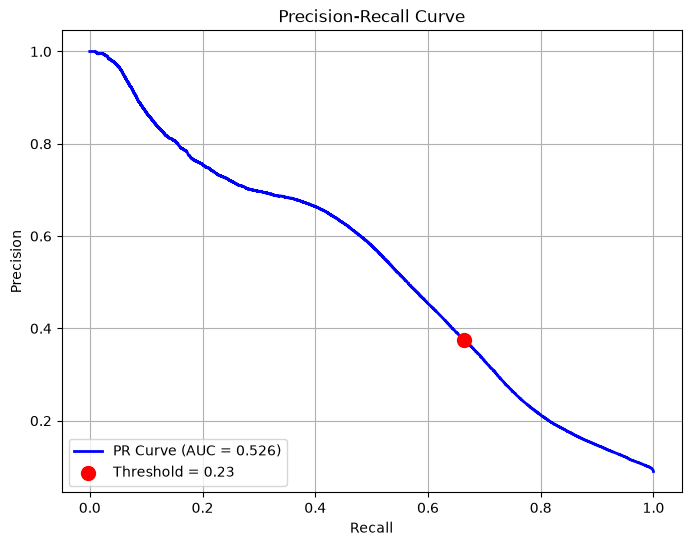

In [32]:
precision, recall, thresholds = precision_recall_curve(y_test, y_pred_random_light)

pr_auc = auc(recall, precision)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'PR Curve (AUC = {pr_auc:.3f})', color='b', lw=2)

target_threshold = threshold
idx = np.argmin(np.abs(thresholds - target_threshold))


plt.scatter(recall[idx], precision[idx], color='red', s=100, label=f'Threshold = {target_threshold:.2f}', zorder=5)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()

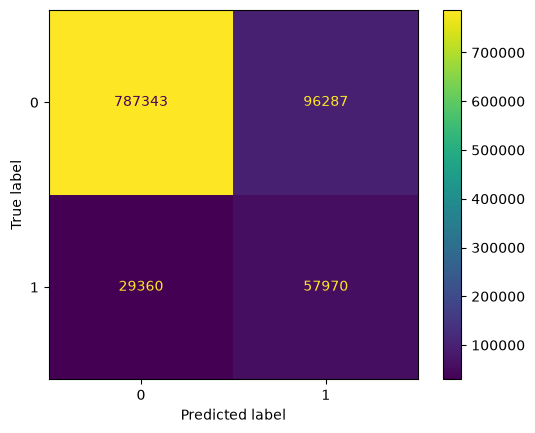

In [33]:
test_pred = (y_pred_random_light >= threshold).astype(int)
ConfusionMatrixDisplay.from_predictions(y_test, test_pred)

Feature importance describes how the fitted model uses these features.

It does not show that a feature causes churn.

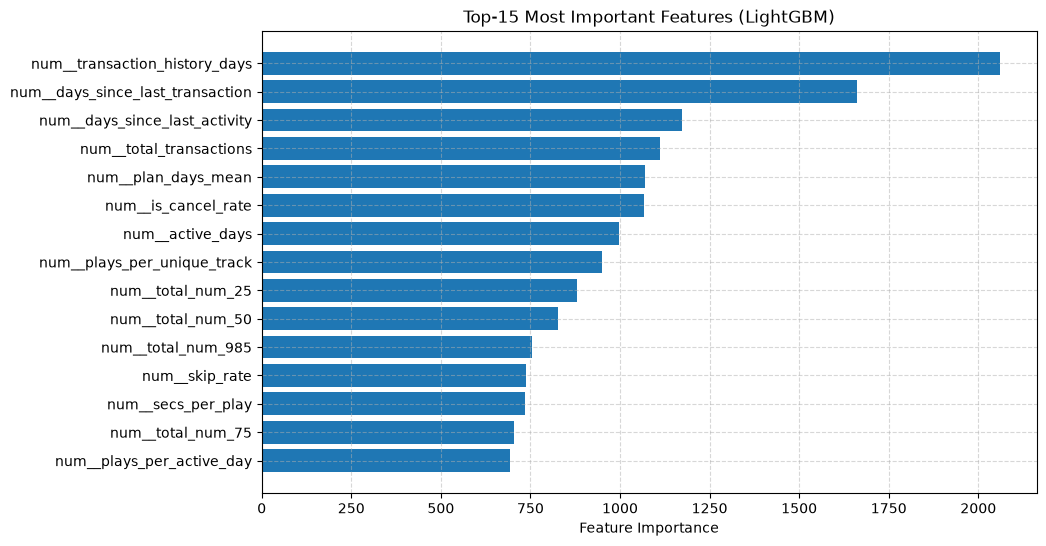

In [34]:
final_light = random_light.named_steps['classifier']
preprocessor = random_light.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()
importances = final_light.feature_importances_

df_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(df_importance['feature'][:15][::-1], df_importance['importance'][:15][::-1])
plt.xlabel('Feature Importance')
plt.title('Top-15 Most Important Features (LightGBM)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

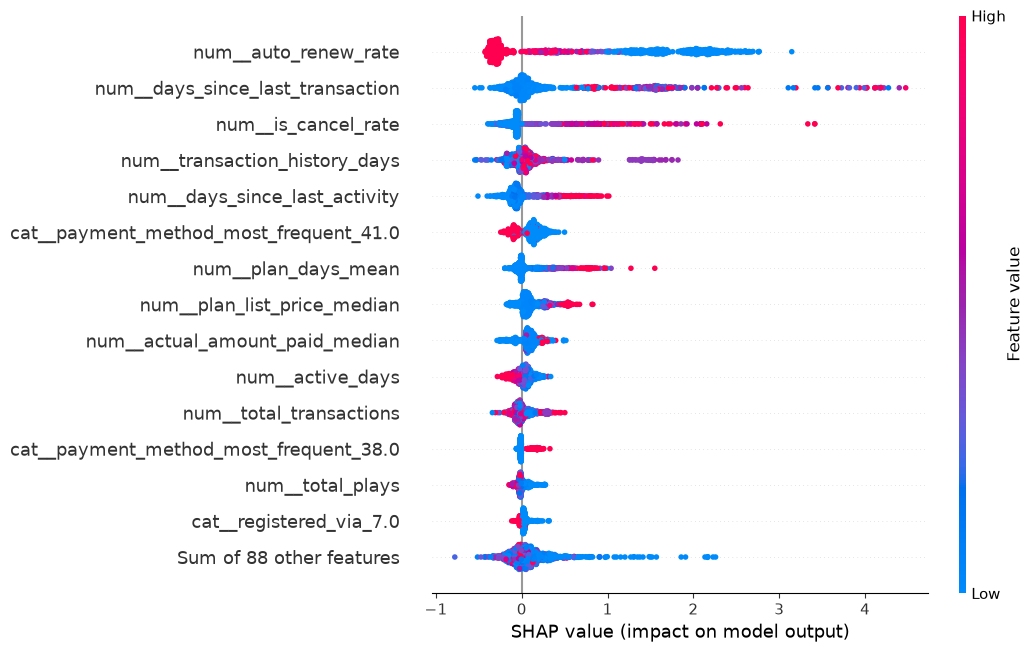

In [35]:
X_test_transformed = preprocessor.transform(X_test)

explainer = shap.TreeExplainer(final_light)

shap_values = explainer(X_test_transformed[:1000])

if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

shap_values.feature_names = list(feature_names)

shap.plots.beeswarm(shap_values, max_display=15)

### Interpretation note: 

- The feature cutoff restricts the model to information available at the intended prediction time. Scores from experiments that included post-cutoff events are not directly comparable, because those events would not be available for a real prediction and may inflate the measured performance. 

- The lower score after applying the cutoff therefore does not, by itself, show that the model is poor. On the March cohort, LightGBM achieved an Average Precision of approximately 0.526, compared with a positive-class prevalence of approximately 0.090. This indicates useful ranking performance under the simulated time constraint. 

- However, Train 2 has been used during model and threshold exploration, so these results should be reported as temporal validation results rather than as a fully independent final evaluation.

In [36]:
import joblib

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

final_model = random_light

model_artifact = {
    "model": final_model,
    "feature_columns": list(X_train.columns),
    "target_column": TARGET_COL,
    "id_column": ID_COL,
}

joblib.dump(model_artifact, model_dir / "lightgbm_pipeline.joblib")

['../models/lightgbm_pipeline.joblib']